In [1]:
#import pandas, numpy, sklearn, matplotlib, uci machine learning.
#check pip list in terminal to make sure libraries are installed

%pip list

Package                 Version
----------------------- ----------
asttokens               3.0.2
certifi                 2026.10.23
cloudpickle             3.1.2
comm                    0.2.3
contourpy               1.4.0
cycler                  0.12.1
debugpy                 1.8.22
et_xmlfile              2.0.0
executing               2.3.0
fonttools               4.68.0
iniconfig               2.3.1
ipykernel               7.4.0
ipython                 9.18.1
ipython_pygments_lexers 1.1.1
jedi                    0.20.1
joblib                  1.6.0
jupyter_client          8.10.0
jupyter_core            5.9.1
kiwisolver              1.5.1
llvmlite                0.50.0
matplotlib              3.11.2
matplotlib-inline       0.2.2
narwhals                2.28.0
nest-asyncio2           1.7.4
numba                   0.68.1
numpy                   2.5.5
openpyxl                3.1.5
packaging               26.3
pandas                  2.3.3
parso                   0.8.7
pexpect            

In [2]:
# Fetch the UCI dataset (ID = 352)

import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from pyclustertend import hopkins

online_retail = fetch_ucirepo(id = 352)

In [3]:
#Data cleaning
# 1. Load the complete dataset (including InvoiceNo)
df = online_retail.data.original.copy()

# 2. Clean raw transactions: drop missing IDs, cancelled orders, and negative/zero values
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]


In [4]:
#Feature engineering
# 1. Calculate total spend per row and convert InvoiceDate
df['TotalSpend'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 2. Engineer Customer-Level RFM Features
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                   # Frequency
    'TotalSpend': 'sum'                                       # Monetary
}).rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalSpend': 'Monetary'
})

# 3. Log-transform to handle right-skewness and scale features
rfm_log = np.log1p(rfm)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# 4. Compute the Hopkins Statistic (using 10% sample size)
sample_size = int(len(rfm_scaled) * 0.10)
h_score = hopkins(rfm_scaled, sample_size)

print(f"Total Unique Customers: {len(rfm_scaled)}")
print(f"Hopkins Statistic (pyclustertend): {h_score:.4f}")

Total Unique Customers: 4338
Hopkins Statistic (pyclustertend): 0.0472


/tmp/ipykernel_84311/3387051086.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)


Now that we know the data is good for clustering, we're going to find the optimal number of clusters for this data.

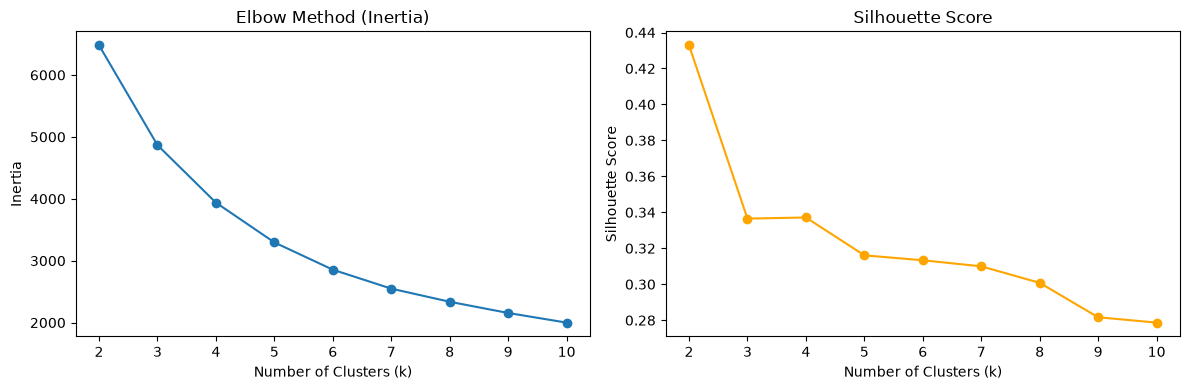

In [5]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
sil_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(rfm_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

# Plot both metrics side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(k_range, inertia, marker='o')
ax1.set_title('Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')

ax2.plot(k_range, sil_scores, marker='o', color='orange')
ax2.set_title('Silhouette Score')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


In [6]:
# 1. Fit the final K-Means model with k=3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# 2. Summarize the average RFM values and customer count per cluster
profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)

print(profile)


        Recency Frequency Monetary      
           mean      mean     mean count
Cluster                                 
0          17.1      13.3   7905.4   770
1         167.4       1.4    362.5  1872
2          44.2       3.4   1265.1  1696


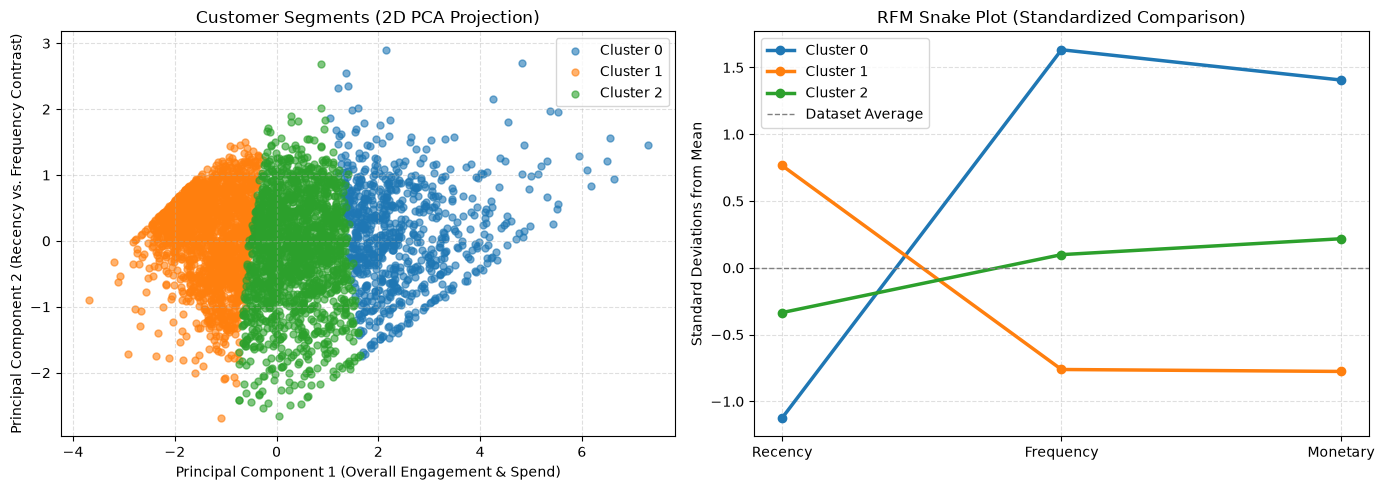

In [7]:
from sklearn.decomposition import PCA

# 1. Reduce scaled RFM features to 2 dimensions for plotting
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(rfm_scaled)

plot_df = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
plot_df['Cluster'] = rfm['Cluster'].values
plot_df['PCA1'] = pca_coords[:, 0]
plot_df['PCA2'] = pca_coords[:, 1]

# 2. Set up a 2-panel figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Left Plot: 2D PCA Cluster Separation
for cluster_id in sorted(plot_df['Cluster'].unique()):
    subset = plot_df[plot_df['Cluster'] == cluster_id]
    ax1.scatter(
        subset['PCA1'], subset['PCA2'],
        label=f'Cluster {cluster_id}',
        color=colors[cluster_id], alpha=0.6, s=25
    )

ax1.set_title('Customer Segments (2D PCA Projection)')
ax1.set_xlabel('Principal Component 1 (Overall Engagement & Spend)')
ax1.set_ylabel('Principal Component 2 (Recency vs. Frequency Contrast)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.4)

# Right Plot: Snake Plot (Standardized RFM Profiles)
snake_data = plot_df.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

for cluster_id in sorted(snake_data.index):
    ax2.plot(
        ['Recency', 'Frequency', 'Monetary'],
        snake_data.loc[cluster_id],
        marker='o', linewidth=2.5,
        label=f'Cluster {cluster_id}',
        color=colors[cluster_id]
    )

ax2.axhline(0, color='gray', linestyle='--', linewidth=1, label='Dataset Average')
ax2.set_title('RFM Snake Plot (Standardized Comparison)')
ax2.set_ylabel('Standard Deviations from Mean')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


These customers can be split into three segments: Wholesale VIPs, Regulars, One-Time Shoppers.

Wholesale VIPs last purchased goods within 15-25 days, placed 10 or more orders, and spent $5000 plus. This is the smallest segment by headcount, but generates the bulk of store revenue.

Regulars last purchased goods within the last 45 to 70 days, placed 3 to 4 orders, and spent between $1000 and $1500. The middle tier represents repeat shoppers and makes up about 40% of the customer base. Loyalty perks or bundled offers can move the top end of this group into the VIP tier.

One-Time Shoppers haven't purchased in a while (160 to 200+ days), placed no more than 2 orders, and spent $300 to $500. The largest group of customers, and many buy during the holidays or other special occasions. One-Time Shoppers are a good candidate for low-cost re-engagement emails.